# Discrete Mathematics: Graph Theory

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising graph theory (part of *Discrete Structures* in BS AI / BS CS / BS Data Science) for an exam or interview.
>
> **What you will learn**
> - The vocabulary: degree, the **handshake lemma**, walks, paths, cycles, connectivity, bridges, **bipartite** graphs and **isomorphism**
> - **Trees**: six equivalent definitions, **Cayley's formula** $n^{n-2}$ (checked by counting, and with Prüfer codes) and the **matrix-tree theorem**
> - **Euler** circuits (Hierholzer's algorithm, de Bruijn sequences) versus **Hamiltonian** cycles (and why the second is hard)
> - **Graph colouring**: greedy colouring and its pitfalls, exact chromatic number, exam timetabling and register allocation
> - **Planarity**: Euler's formula V − E + F = 2, why K₅ and K₃,₃ are not planar
> - **Matchings**: Hall's marriage theorem, augmenting paths and **König's theorem**
> - **Spectral graph theory**: the Laplacian, counting components from eigenvalue 0, the **Fiedler vector** for cutting a graph in two, and the link to spectral clustering and graph neural networks
> - **Random graphs**: the Erdős–Rényi phase transition, small worlds and scale-free networks
> - **PageRank** as a Markov chain, computed from scratch
>
> **Prerequisites:** [`01_sets_relations_functions_and_proofs.ipynb`](01_sets_relations_functions_and_proofs.ipynb) (relations, proofs) and [`02_combinatorics_and_recurrences.ipynb`](02_combinatorics_and_recurrences.ipynb) (counting). Helpful: [`14_Mathematics/01_linear_algebra.ipynb`](../01_linear_algebra.ipynb) (eigenvalues, for Section 10) and the graph *algorithms* notebook [`dsa/07_graphs.ipynb`](../../00_AI_Fundamentals/dsa/07_graphs.ipynb) (BFS, DFS, shortest paths, minimum spanning trees).
>
> **Time needed:** about 3 to 4 hours.
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, numpy, pandas, matplotlib, networkx. The notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Rosen, *Discrete Mathematics and Its Applications* (8th ed.), chapters 10–11, and D. B. West, *Introduction to Graph Theory* (2nd ed.).

## Explained simply

A **graph** is a set of dots (called vertices or nodes) joined by lines (called edges). That simple picture describes an amazing number of things: people and friendships, cities and roads, web pages and links, atoms and chemical bonds. **Graph theory** asks questions about these pictures: can I visit every road exactly once? How few colours do I need so that neighbours never share a colour? Which single road, if closed, would split the city in two? Many of these questions have neat answers, and a few are famously hard, which tells engineers where to use exact algorithms and where to settle for good-enough ones.

**Everyday examples.**
- A delivery driver who wants to drive down every street exactly once is asking for an **Euler circuit**; a salesperson who wants to visit every city exactly once is asking for a **Hamiltonian cycle**. The first is easy, the second is very hard.
- A school making an exam timetable draws a line between two exams whenever some student takes both; exams joined by a line need different time slots. That is **graph colouring**.
- In a social network, "six degrees of separation" (any two people are linked by a short chain of friends) is the **small-world** property of random graphs.

**A tiny example.** Four friends: Ali knows Sara and Bilal, Sara knows Bilal, and Zoya knows only Sara. Count each person's friends: Ali 2, Sara 3, Bilal 2, Zoya 1. The total is 8, which is exactly twice the 4 friendships, because each friendship is counted once from each side. That is the **handshake lemma**, and it means the total number of friend-counts is always even.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Graph, degree, path | dots, lines, how many lines touch a dot, a route along lines | maps and social networks; knowledge graphs |
| Colouring, matching | give neighbours different labels; pair things up without sharing | timetables; assigning drivers to riders or GPUs to jobs |
| Spectral graph theory, random graphs | read a graph's shape from the numbers in its matrix; how networks look when links are random | spectral clustering, graph neural networks, PageRank |

### How this notebook is different from `dsa/07`
[`dsa/07_graphs`](../../00_AI_Fundamentals/dsa/07_graphs.ipynb) is about **algorithms** on graphs: representations, BFS/DFS, Dijkstra, Bellman–Ford, topological sort, union-find, minimum spanning trees. This notebook is about the **mathematics** of graphs: theorems (handshake, Euler, Cayley, Hall, König, Euler's formula), proofs, counting, colouring, planarity and spectra. We use small from-scratch algorithms to *check* the theorems, and networkx to cross-check. Network flows and the Hungarian algorithm are in [`advanced_algorithms/04`](../../00_AI_Fundamentals/advanced_algorithms/04_network_flows_and_matching.ipynb); NP-completeness is in [`advanced_algorithms/02`](../../00_AI_Fundamentals/advanced_algorithms/02_np_completeness_and_reductions.ipynb).

## Table of contents
1. Graphs, degrees and the handshake lemma
2. Walks, paths, cycles and connectivity
3. Bipartite graphs
4. Graph isomorphism
5. Trees and spanning trees
6. Euler circuits and Hamiltonian cycles
7. Graph colouring
8. Planar graphs and Euler's formula
9. Matchings: Hall's and König's theorems
10. Spectral graph theory
11. Random graphs
12. Summary of theorems
13. How this connects to modern AI (with PageRank from scratch)
14. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from itertools import combinations, permutations, product
from collections import deque, Counter, defaultdict
import networkx as nx

def draw(G, ax, title, pos=None, node_color=None, with_labels=True, node_size=300, **kw):
    """Small helper so every graph drawing in this notebook looks the same."""
    pos = pos or nx.spring_layout(G, seed=1)
    nx.draw_networkx(G, pos, ax=ax, with_labels=with_labels, node_size=node_size, font_size=8,
                     node_color=node_color if node_color is not None else PALETTE[0],
                     font_color="white", edge_color="#555555", **kw)
    ax.set_title(title, fontsize=10); ax.axis("off")
    return pos

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Graphs, degrees and the handshake lemma

> **In plain English:** a graph is dots joined by lines; counting the lines at each dot always gives twice the number of lines.

**Definitions.**
- A **graph** $G = (V, E)$ is a set of **vertices** V and a set of **edges** E, each edge joining two vertices. In a **simple graph** edges are unordered pairs {u, v} with u ≠ v and no repeats. A **multigraph** allows parallel edges (and sometimes loops). In a **directed graph** (digraph) edges are ordered pairs (u, v). A **weighted** graph puts a number on each edge.
- u and v are **adjacent** (neighbours) if {u, v} ∈ E. The **degree** deg(v) is the number of edges at v (a loop counts 2). In a digraph, in-degree and out-degree.
- Notation: n = |V| (the **order**), m = |E| (the **size**). A simple graph has at most $\binom{n}{2}$ edges.

**Handshake lemma.** In any undirected graph, $\displaystyle\sum_{v \in V} \deg(v) = 2|E|$.

*Proof.* Each edge {u, v} adds exactly 1 to deg(u) and 1 to deg(v), so it contributes exactly 2 to the sum. ∎

**Corollary.** Every graph has an **even number of odd-degree vertices** (the sum of degrees is even, and the even degrees contribute an even amount). So, for example, there is no group of 7 people in which everyone knows exactly 3 others (7 × 3 = 21 is odd).

Standard graphs you must recognise:

| Name | Notation | n | m | Description |
|---|---|---|---|---|
| Complete graph | $K_n$ | n | $\binom{n}{2}$ | every pair joined |
| Cycle | $C_n$ | n | n | a ring |
| Path | $P_n$ | n | n − 1 | a line |
| Complete bipartite | $K_{a,b}$ | a + b | ab | every left vertex joined to every right vertex |
| Hypercube | $Q_d$ | $2^d$ | $d\,2^{d-1}$ | bit strings, joined if they differ in one bit |
| Petersen graph | | 10 | 15 | the standard counterexample of graph theory |

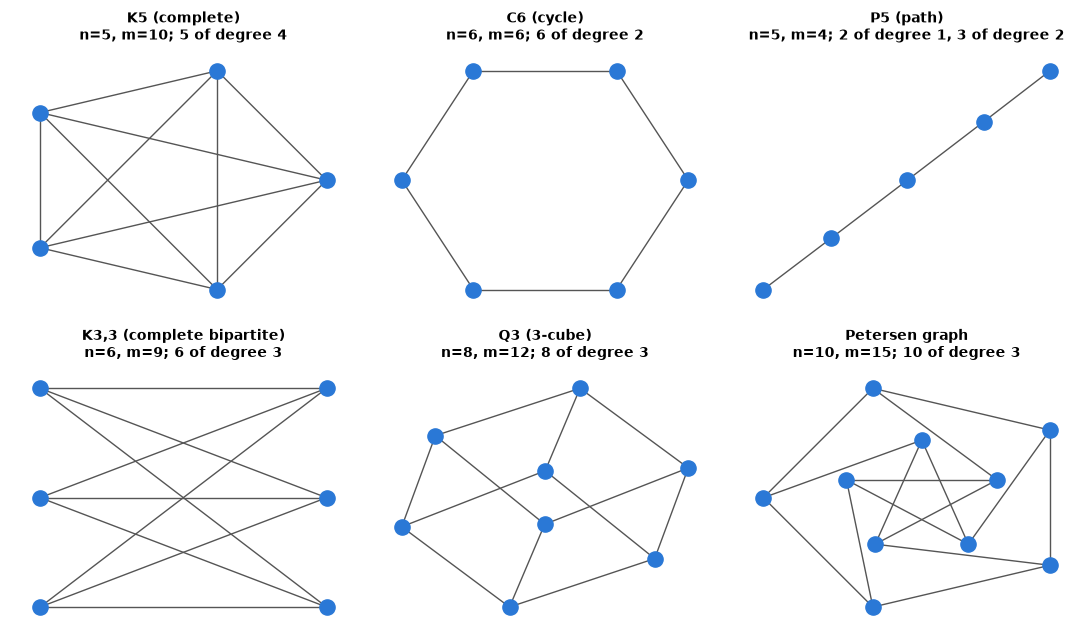

handshake lemma and the odd-degree corollary held on 500 random graphs and a multigraph


In [2]:
gallery = {
    "K5 (complete)": (nx.complete_graph(5), None),
    "C6 (cycle)": (nx.cycle_graph(6), None),
    "P5 (path)": (nx.path_graph(5), None),
    "K3,3 (complete bipartite)": (nx.complete_bipartite_graph(3, 3), "bip"),
    "Q3 (3-cube)": (nx.hypercube_graph(3), None),
    "Petersen graph": (nx.petersen_graph(), "shell"),
}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, (name, (G, layout)) in zip(axes.flat, gallery.items()):
    if layout == "bip":
        pos = nx.bipartite_layout(G, range(3))
    elif layout == "shell":
        pos = nx.shell_layout(G, [range(5, 10), range(5)])
    elif name.startswith(("K5", "C6")):
        pos = nx.circular_layout(G)
    else:
        pos = nx.spring_layout(G, seed=3)
    degs = sorted(d for _, d in G.degree())
    deg_text = ", ".join(f"{cnt} of degree {d}" for d, cnt in sorted(Counter(degs).items()))
    draw(G, ax, f"{name}\nn={G.number_of_nodes()}, m={G.number_of_edges()}; {deg_text}",
         pos=pos, with_labels=False, node_size=120)
plt.tight_layout(); plt.show()

# Handshake lemma on random graphs (including multigraphs with parallel edges)
rng = random.Random(0)
for trial in range(500):
    n = rng.randint(1, 30)
    G = nx.gnp_random_graph(n, rng.random(), seed=trial)
    degs = [d for _, d in G.degree()]
    assert sum(degs) == 2 * G.number_of_edges()
    assert sum(1 for d in degs if d % 2 == 1) % 2 == 0
M = nx.MultiGraph([(0, 1), (0, 1), (1, 2), (2, 2)])      # parallel edge and a loop (counts 2)
assert sum(d for _, d in M.degree()) == 2 * M.number_of_edges()
print("handshake lemma and the odd-degree corollary held on 500 random graphs and a multigraph")

### Which degree sequences are possible?
A list of numbers is **graphical** if some simple graph has exactly those degrees. The handshake lemma gives a necessary condition (even sum), but it is not sufficient: (3, 3, 1, 1) has an even sum yet no simple graph has it (the two degree-3 vertices would each need 3 distinct neighbours among only 3 other vertices, which forces both degree-1 vertices to have degree 2).

**Havel–Hakimi theorem (1955, 1962).** A non-increasing sequence $d_1 \ge d_2 \ge \dots \ge d_n$ is graphical iff the sequence obtained by deleting $d_1$ and subtracting 1 from the next $d_1$ entries is graphical. This gives a simple recursive test (and builds the graph as it goes: join the biggest-degree vertex to the next biggest ones).

In [3]:
def havel_hakimi(seq):
    """True iff `seq` is the degree sequence of some simple graph."""
    seq = sorted(seq, reverse=True)
    while seq and seq[0] > 0:
        d = seq.pop(0)                       # vertex with the largest remaining degree
        if d > len(seq):
            return False                     # not enough other vertices to connect to
        for i in range(d):
            seq[i] -= 1                      # connect it to the d next-largest vertices
            if seq[i] < 0:
                return False
        seq.sort(reverse=True)
    return all(x == 0 for x in seq)

examples = [[3, 3, 1, 1], [3, 3, 2, 2], [3, 3, 3, 3], [4, 4, 4, 1, 1], [2, 2, 2], [5, 3, 2, 2, 1, 1]]
for s_ in examples:
    print(s_, "graphical?", havel_hakimi(s_), "| networkx:", nx.is_graphical(s_))
rng = random.Random(1)
for _ in range(3000):
    s_ = [rng.randint(0, 7) for _ in range(rng.randint(1, 9))]
    assert havel_hakimi(s_) == nx.is_graphical(s_)
print("agrees with networkx.is_graphical on 3000 random sequences")

[3, 3, 1, 1] graphical? False | networkx: False
[3, 3, 2, 2] graphical? True | networkx: True
[3, 3, 3, 3] graphical? True | networkx: True
[4, 4, 4, 1, 1] graphical? False | networkx: False
[2, 2, 2] graphical? True | networkx: True
[5, 3, 2, 2, 1, 1] graphical? True | networkx: True


agrees with networkx.is_graphical on 3000 random sequences


---
## 2. Walks, paths, cycles and connectivity

> **In plain English:** routes through a graph, and whether you can get from anywhere to anywhere.

| Term | Definition |
|---|---|
| **Walk** | a sequence of vertices $v_0, v_1, \dots, v_k$ with each consecutive pair adjacent; its **length** is k (edges, repeats allowed) |
| **Trail** | a walk with no repeated **edge** |
| **Path** | a walk with no repeated **vertex** |
| **Closed walk / circuit** | a walk / trail that ends where it starts |
| **Cycle** | a closed walk of length ≥ 3 with no repeated vertex except start = end |
| **Connected** | there is a path between every pair of vertices |
| **Connected component** | a maximal connected subgraph ("is connected to" is an equivalence relation; its classes are the components) |
| **Distance** d(u, v) | length of a shortest path; the **diameter** is the largest distance |
| **Bridge** / **cut vertex** | an edge / vertex whose removal increases the number of components |

**Theorem (walks and matrix powers).** If A is the adjacency matrix, then $(A^k)_{ij}$ = the number of walks of length k from i to j.
*Proof by induction on k:* a walk of length k + 1 from i to j is a walk of length k from i to some l followed by an edge l → j, so the count is $\sum_l (A^k)_{il}A_{lj} = (A^{k+1})_{ij}$. ∎

One consequence: $\operatorname{trace}(A^3)/6$ = the number of triangles (each triangle gives 6 closed walks of length 3: 3 starting points × 2 directions).

In [4]:
def count_walks(G, i, j, k):
    """Brute force: count walks of length k from i to j by exploring every possible step."""
    if k == 0:
        return int(i == j)
    return sum(count_walks(G, nb_, j, k - 1) for nb_ in G[i])

G = nx.petersen_graph()
A = nx.to_numpy_array(G, nodelist=sorted(G), dtype=int)
for k in range(1, 6):
    Ak = np.linalg.matrix_power(A, k)
    assert all(Ak[i, j] == count_walks(G, i, j, k) for i in range(10) for j in range(10))
print("(A^k)_ij = number of walks of length k: verified on the Petersen graph for k = 1..5")
for name, H in {"K5": nx.complete_graph(5), "Petersen": G, "random G(30, 0.2)": nx.gnp_random_graph(30, 0.2, seed=2)}.items():
    A_ = nx.to_numpy_array(H, dtype=int)
    print(f"{name:18s} triangles: trace(A^3)/6 = {int(np.trace(np.linalg.matrix_power(A_, 3))) // 6:4d} | networkx: {sum(nx.triangles(H).values()) // 3}")

def components(G):
    """Connected components by BFS from every unvisited vertex. O(n + m)."""
    seen, comps = set(), []
    for s in G:
        if s in seen:
            continue
        comp, queue = [], deque([s])
        seen.add(s)
        while queue:
            v = queue.popleft()
            comp.append(v)
            for w in G[v]:
                if w not in seen:
                    seen.add(w); queue.append(w)
        comps.append(set(comp))
    return comps

def bridges_brute(G):
    """An edge is a bridge if deleting it increases the number of components. O(m (n + m))."""
    base = len(components(G))
    out = set()
    for u, v in list(G.edges()):
        H = G.copy(); H.remove_edge(u, v)
        if len(components(H)) > base:
            out.add(frozenset((u, v)))
    return out

for seed in range(100):
    H = nx.gnp_random_graph(15, 0.15, seed=seed)
    assert sorted(map(sorted, components(H))) == sorted(map(sorted, nx.connected_components(H)))
    assert bridges_brute(H) == {frozenset(e) for e in nx.bridges(H)}
print("BFS components and brute-force bridges match networkx on 100 random graphs")

(A^k)_ij = number of walks of length k: verified on the Petersen graph for k = 1..5


K5                 triangles: trace(A^3)/6 =   10 | networkx: 10
Petersen           triangles: trace(A^3)/6 =    0 | networkx: 0
random G(30, 0.2)  triangles: trace(A^3)/6 =   29 | networkx: 29


BFS components and brute-force bridges match networkx on 100 random graphs


**What just happened?** Matrix powers counted walks exactly as the induction proof says, and $\operatorname{trace}(A^3)/6$ counted triangles (the Petersen graph has none: its shortest cycle, the **girth**, is 5). Our BFS components and brute-force bridges match networkx. The brute-force bridge finder costs O(m(n + m)); Tarjan's DFS low-link algorithm (used by `nx.bridges`) finds all bridges in O(n + m).

> 🎓 **Exam / interview tip:** a connected graph with n vertices has **at least n − 1 edges**, and a graph with n vertices and more than $\binom{n-1}{2}$ edges is **always connected**. Both are favourite short-proof questions.

---
## 3. Bipartite graphs

> **In plain English:** a graph is bipartite if its dots split into two teams with lines only between teams, which is possible exactly when there is no odd loop.

**Definition.** G is **bipartite** if V can be split into two sets L and R so that every edge goes between L and R (no edge inside a side). Examples: students and courses, users and items in a recommender, $K_{a,b}$, every tree, every even cycle, the hypercube.

**Theorem (König, 1936).** A graph is bipartite **iff it has no odd cycle.**

*Proof sketch.* (⇒) Walking around a cycle alternates sides, so you return to the starting side only after an even number of steps. (⇐) In each component, pick a root and put vertices at even BFS distance in L and odd distance in R. If an edge joined two vertices on the same side, the two BFS paths to them plus that edge would contain an odd cycle. ∎

The proof is an algorithm: BFS 2-colouring, which either returns the two sides or an **odd cycle as a certificate** that none exist.

In [5]:
def bipartition_or_odd_cycle(G):
    """Return ('bipartite', L, R) or ('odd cycle', cycle). BFS 2-colouring, O(n + m)."""
    side, parent = {}, {}
    for s in G:
        if s in side:
            continue
        side[s], parent[s] = 0, None
        queue = deque([s])
        while queue:
            v = queue.popleft()
            for w in G[v]:
                if w not in side:
                    side[w], parent[w] = 1 - side[v], v
                    queue.append(w)
                elif side[w] == side[v]:                    # conflict: build the odd cycle
                    path_v, path_w = [v], [w]
                    while path_v[-1] is not None: path_v.append(parent[path_v[-1]])
                    while path_w[-1] is not None: path_w.append(parent[path_w[-1]])
                    path_v, path_w = path_v[:-1], path_w[:-1]
                    common = next(x for x in path_v if x in set(path_w))   # lowest common ancestor
                    cyc = path_v[: path_v.index(common) + 1] + path_w[: path_w.index(common)][::-1]
                    return ("odd cycle", cyc)
    return ("bipartite", {v for v in side if side[v] == 0}, {v for v in side if side[v] == 1})

for name, H in {"C6": nx.cycle_graph(6), "C7": nx.cycle_graph(7), "Q3": nx.hypercube_graph(3),
                "Petersen": nx.petersen_graph(), "a random tree": nx.random_labeled_tree(9, seed=1)}.items():
    res = bipartition_or_odd_cycle(H)
    print(f"{name:14s} -> {res[0]}" + (f", odd cycle {res[1]} (length {len(res[1])})" if res[0] == "odd cycle" else ""))

for seed in range(300):
    H = nx.gnp_random_graph(12, 0.2, seed=seed)
    res = bipartition_or_odd_cycle(H)
    assert (res[0] == "bipartite") == nx.is_bipartite(H)
    if res[0] == "odd cycle":
        cyc = res[1]
        assert len(cyc) % 2 == 1 and len(set(cyc)) == len(cyc)
        assert all(H.has_edge(cyc[i], cyc[(i + 1) % len(cyc)]) for i in range(len(cyc)))
    else:
        L, R = res[1], res[2]
        assert all((u in L) != (v in L) for u, v in H.edges())
print("verified on 300 random graphs: every 'odd cycle' answer is a real odd cycle, every bipartition is valid")

C6             -> bipartite
C7             -> odd cycle, odd cycle [3, 2, 1, 0, 6, 5, 4] (length 7)
Q3             -> bipartite
Petersen       -> odd cycle, odd cycle [2, 1, 0, 4, 3] (length 5)
a random tree  -> bipartite
verified on 300 random graphs: every 'odd cycle' answer is a real odd cycle, every bipartition is valid


---
## 4. Graph isomorphism

> **In plain English:** two graphs are 'the same' if you can relabel one to get the other; proving it needs the relabelling, not just matching counts.

**Definition.** Graphs G and H are **isomorphic** ($G \cong H$) if there is a bijection $f: V(G) \to V(H)$ such that {u, v} is an edge of G **iff** {f(u), f(v)} is an edge of H. Isomorphic graphs are "the same drawing with different labels".

**Invariants** are properties that isomorphic graphs must share: number of vertices and edges, degree sequence, number of triangles, number of components, bipartiteness, girth, eigenvalues of A. If an invariant differs, the graphs are **not** isomorphic. If all invariants you checked agree, you still have not proved isomorphism: you must exhibit the bijection.

Example: the 6-cycle $C_6$ and two disjoint triangles $2K_3$ both have 6 vertices, 6 edges and every degree equal to 2, but $C_6$ is connected and $2K_3$ is not (and $2K_3$ has triangles).

**Complexity.** Testing isomorphism is in NP (a bijection is a certificate), but it is not known to be NP-complete or in P. László Babai (2015, corrected 2017) gave a **quasi-polynomial** $2^{O((\log n)^c)}$ algorithm. Brute force tries all n! bijections.

In [6]:
def isomorphic_brute(G, H):
    """Try every bijection. Returns a mapping or None. O(n! * m)."""
    if G.number_of_nodes() != H.number_of_nodes() or G.number_of_edges() != H.number_of_edges():
        return None
    if sorted(d for _, d in G.degree()) != sorted(d for _, d in H.degree()):
        return None                                             # quick invariant check first
    gv, hv = list(G), list(H)
    H_edges = {frozenset(e) for e in H.edges()}
    for perm in permutations(hv):
        f = dict(zip(gv, perm))
        if all(frozenset((f[u], f[v])) in H_edges for u, v in G.edges()):
            return f
    return None

C6 = nx.cycle_graph(6)
twoK3 = nx.disjoint_union(nx.complete_graph(3), nx.complete_graph(3))
relabelled = nx.relabel_nodes(nx.petersen_graph(), dict(zip(range(10), random.Random(5).sample(range(10), 10))))
print("C6 ≅ 2K3 ?", isomorphic_brute(C6, twoK3) is not None, "| networkx:", nx.is_isomorphic(C6, twoK3))
f = isomorphic_brute(nx.petersen_graph(), relabelled)
print("Petersen ≅ shuffled Petersen ?", f is not None, "| a bijection:", f)

def canonical_form(n, edges):
    """Smallest edge-bitmask over all relabellings: equal iff the graphs are isomorphic."""
    pairs = list(combinations(range(n), 2))
    index = {p: i for i, p in enumerate(pairs)}
    best = None
    for perm in permutations(range(n)):
        mask = 0
        for u, v in edges:
            a, b = sorted((perm[u], perm[v]))
            mask |= 1 << index[(a, b)]
        best = mask if best is None or mask < best else best
    return best

for n in [3, 4, 5]:
    pairs = list(combinations(range(n), 2))
    classes = {canonical_form(n, [pairs[i] for i in range(len(pairs)) if mask >> i & 1])
               for mask in range(2 ** len(pairs))}
    print(f"n = {n}: {2 ** len(pairs):5d} labelled graphs fall into {len(classes)} isomorphism classes")

C6 ≅ 2K3 ? False | networkx: False
Petersen ≅ shuffled Petersen ? True | a bijection: {0: 9, 1: 4, 2: 5, 3: 6, 4: 7, 5: 8, 6: 0, 7: 1, 8: 3, 9: 2}
n = 3:     8 labelled graphs fall into 4 isomorphism classes
n = 4:    64 labelled graphs fall into 11 isomorphism classes


n = 5:  1024 labelled graphs fall into 34 isomorphism classes


**What just happened?** Brute force correctly said $C_6 \not\cong 2K_3$ (no bijection works, even though the degree sequences match) and found a bijection between the Petersen graph and a shuffled copy. Grouping all labelled graphs by a **canonical form** shows that the 64 labelled graphs on 4 vertices are only **11** different shapes, and the 1,024 on 5 vertices are **34** shapes.

> ⚠️ **Common mistake:** concluding "isomorphic" because the degree sequences match. Matching invariants are necessary, never sufficient. To prove isomorphism, give the bijection and check the edges.

---
## 5. Trees and spanning trees

> **In plain English:** a tree is a connected graph with no loops; there are exactly nⁿ⁻² of them on n labelled dots.

**Definition.** A **tree** is a connected graph with no cycles. A **forest** is a graph with no cycles (its components are trees). A **leaf** is a vertex of degree 1.

**Theorem (characterisations of trees).** For a graph T with n vertices, the following are equivalent:
1. T is connected and acyclic;
2. T is connected and has exactly n − 1 edges;
3. T is acyclic and has exactly n − 1 edges;
4. there is exactly one path between every pair of vertices;
5. T is **minimally connected**: removing any edge disconnects it;
6. T is **maximally acyclic**: adding any edge creates exactly one cycle.

Also, every tree with n ≥ 2 vertices has **at least two leaves** (the two ends of a longest path).

A **spanning tree** of a connected graph G is a subgraph that is a tree and contains every vertex. Every connected graph has one (BFS or DFS gives one; Kruskal and Prim give a *minimum-weight* one, see [`dsa/07`](../../00_AI_Fundamentals/dsa/07_graphs.ipynb)).

We check the equivalences on thousands of random small graphs: for every graph, the six properties must be either all true or all false.

In [7]:
def is_acyclic(G):
    return G.number_of_edges() == G.number_of_nodes() - nx.number_connected_components(G)   # forest test

def unique_paths(G):
    return all(len(list(nx.all_simple_paths(G, u, v))) == 1 for u, v in combinations(G, 2))

def minimally_connected(G):
    if not nx.is_connected(G):
        return False
    return all(not nx.is_connected(nx.restricted_view(G, [], [e])) for e in G.edges())

def maximally_acyclic(G):
    if not is_acyclic(G):
        return False
    def with_edge(u, v):
        H = G.copy(); H.add_edge(u, v)
        return H
    return all(not is_acyclic(with_edge(u, v)) for u, v in nx.non_edges(G))

def six_properties(G):
    n, m = G.number_of_nodes(), G.number_of_edges()
    con, acyc = nx.is_connected(G), is_acyclic(G)
    return [con and acyc, con and m == n - 1, acyc and m == n - 1,
            unique_paths(G), minimally_connected(G), maximally_acyclic(G)]

rng = random.Random(3)
counts = Counter()
for trial in range(1500):
    n = rng.randint(2, 7)
    if trial % 2:
        G = nx.random_labeled_tree(n, seed=trial)                              # half of them are trees
        if rng.random() < 0.5:                                                 # ... some with one change
            G.add_edge(*rng.sample(range(n), 2)) if rng.random() < 0.5 else G.remove_edge(*next(iter(G.edges())))
    else:
        G = nx.gnp_random_graph(n, rng.random(), seed=trial)
    props = six_properties(G)
    assert all(props) or not any(props), (props, list(G.edges()))
    counts["tree" if props[0] else "not a tree"] += 1
print("the six characterisations agreed on all 1500 graphs:", dict(counts))

the six characterisations agreed on all 1500 graphs: {'not a tree': 910, 'tree': 590}


### Cayley's formula: counting labelled trees
**Theorem (Cayley, 1889).** There are exactly $n^{n-2}$ different trees on n labelled vertices. Equivalently, the complete graph $K_n$ has $n^{n-2}$ spanning trees.

| n | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|
| $n^{n-2}$ | 1 | 3 | 16 | 125 | 1296 |

**Proof idea (Prüfer, 1918).** There is a bijection between labelled trees on {0, …, n−1} and sequences of length n − 2 over {0, …, n−1} (there are $n^{n-2}$ such sequences). **Encode:** repeatedly remove the smallest leaf and write down its neighbour. **Decode:** rebuild the tree from the sequence. We implement both directions, check they are inverses, and count spanning trees of $K_n$ by brute force.

In [8]:
def prufer_encode(T):
    """Tree on vertices 0..n-1 -> Prüfer sequence of length n-2."""
    T = {v: set(T[v]) for v in T}
    seq = []
    for _ in range(len(T) - 2):
        leaf = min(v for v in T if len(T[v]) == 1)       # smallest leaf
        nbr = next(iter(T[leaf]))
        seq.append(nbr)                                  # write down its neighbour
        T[nbr].discard(leaf); del T[leaf]
    return tuple(seq)

def prufer_decode(seq):
    """Prüfer sequence -> list of tree edges."""
    n = len(seq) + 2
    degree = [1] * n
    for x in seq:
        degree[x] += 1                                   # a vertex appears (degree - 1) times
    edges = []
    for x in seq:
        leaf = min(v for v in range(n) if degree[v] == 1)
        edges.append((leaf, x))
        degree[leaf] -= 1; degree[x] -= 1
    u, v = [w for w in range(n) if degree[w] == 1]
    edges.append((u, v))
    return edges

def spanning_trees_brute(G):
    """Count subsets of n-1 edges that form a spanning tree."""
    n = G.number_of_nodes()
    count = 0
    for edges in combinations(G.edges(), n - 1):
        H = nx.Graph(edges); H.add_nodes_from(G)
        if nx.is_connected(H):                           # n-1 edges + connected = tree
            count += 1
    return count

rows = []
for n in range(2, 7):
    Kn = nx.complete_graph(n)
    brute = spanning_trees_brute(Kn)
    seqs = set(product(range(n), repeat=n - 2))
    decoded = [prufer_decode(s) for s in seqs]
    assert all(nx.is_tree(nx.Graph(e)) for e in decoded)
    assert {prufer_encode((nx.Graph(e))) for e in decoded} == seqs     # encode ∘ decode = id
    assert len({frozenset(map(frozenset, e)) for e in decoded}) == len(seqs)            # all trees distinct
    rows.append({"n": n, "spanning trees of K_n (brute force)": brute, "Prüfer sequences": len(seqs), "n^(n-2)": n ** (n - 2)})
display(pd.DataFrame(rows).set_index("n"))
T = nx.Graph([(0, 3), (1, 3), (2, 3), (3, 4), (4, 5)])
print("example tree", sorted(T.edges()), "-> Prüfer", prufer_encode((T)),
      "-> back to", sorted(tuple(sorted(e)) for e in prufer_decode(prufer_encode((T)))))

,spanning trees of K_n (brute force),Prüfer sequences,n^(n-2)
n,,,
2,1,1,1
3,3,3,3
4,16,16,16
5,125,125,125
6,1296,1296,1296


example tree [(0, 3), (3, 1), (3, 2), (3, 4), (4, 5)] -> Prüfer (3, 3, 3, 4) -> back to [(0, 3), (1, 3), (2, 3), (3, 4), (4, 5)]


**What just happened?** Brute force over edge subsets, the number of Prüfer sequences, and $n^{n-2}$ agree for n = 2 … 6, and decoding then encoding returns every sequence unchanged, so the map is a bijection. Notice in the example that the vertex 3 of degree 4 appears 3 times in its Prüfer sequence: **a vertex appears exactly deg − 1 times**.

### The matrix-tree theorem
**Theorem (Kirchhoff, 1847).** For any graph G, the number of spanning trees equals **any cofactor of the Laplacian** $L = D - A$ (delete row i and column i, take the determinant). For $K_n$ this gives $n^{n-2}$ again. The Laplacian returns in Section 10.

In [9]:
def matrix_tree_count(G):
    L = nx.laplacian_matrix(G, nodelist=sorted(G)).toarray().astype(float)
    return round(np.linalg.det(L[1:, 1:]))                  # delete row 0 and column 0

rng = random.Random(4)
for trial in range(60):
    G = nx.gnp_random_graph(7, 0.5, seed=trial)
    if not nx.is_connected(G) or G.number_of_edges() > 14:
        continue
    assert matrix_tree_count(G) == spanning_trees_brute(G)
print("Kirchhoff's cofactor count matches brute force on random 7-vertex graphs")
print("spanning trees: K_10 =", matrix_tree_count(nx.complete_graph(10)), "(10^8),",
      "Petersen =", matrix_tree_count(nx.petersen_graph()), ", 4x4 grid =", matrix_tree_count(nx.grid_2d_graph(4, 4)))

Kirchhoff's cofactor count matches brute force on random 7-vertex graphs
spanning trees: K_10 = 100000000 (10^8), Petersen = 2000 , 4x4 grid = 100352


---
## 6. Euler circuits and Hamiltonian cycles

> **In plain English:** using every line once is easy to decide (check the degrees); visiting every dot once is one of the hardest problems in computing.

**Definitions.** An **Euler circuit** is a closed trail using **every edge** exactly once; an **Euler path** (trail) does the same without returning to the start. A **Hamiltonian cycle** visits **every vertex** exactly once and returns; a **Hamiltonian path** does not need to return.

**The Königsberg bridges (Euler, 1736).** Four land areas joined by seven bridges. Can a walk cross every bridge exactly once? Euler's answer founded graph theory:

**Theorem (Euler; Hierholzer, 1873).** A connected multigraph has an **Euler circuit iff every vertex has even degree**, and an **Euler path iff exactly zero or two vertices have odd degree** (the path then starts and ends at the odd ones).

*Why necessary:* every time the walk passes through a vertex it uses one edge in and one edge out, so the degree must be even (except at the two ends of an open path). *Why sufficient:* Hierholzer's algorithm below constructs the circuit.

Königsberg as a multigraph: island A has 5 bridges, the three other areas have 3 each. Four odd vertices, so no Euler path exists.

```
         C (north bank)
        / | \
       /  |  \        A = island (degree 5)
      A===+---D       B, C, D: degree 3
       \  |  /        (=== means two parallel bridges)
        \ | /
         B (south bank)
```

**Hierholzer's algorithm.** Walk from the start, always taking an unused edge, until you get stuck (you must be back at the start). Then backtrack to a vertex on the current walk that still has unused edges and splice in a new loop from there. With a stack this is O(m).

In [10]:
def euler_circuit(edges, start):
    """Hierholzer's algorithm for an undirected multigraph given as a list of edges. O(m)."""
    adj = defaultdict(list)
    for i, (u, v) in enumerate(edges):
        adj[u].append((v, i)); adj[v].append((u, i))
    used = [False] * len(edges)
    stack, circuit = [start], []
    while stack:
        v = stack[-1]
        while adj[v] and used[adj[v][-1][1]]:
            adj[v].pop()                          # discard edges already used
        if adj[v]:
            w, i = adj[v].pop()
            used[i] = True
            stack.append(w)                       # keep walking
        else:
            circuit.append(stack.pop())           # stuck: this vertex is finished
    return circuit[::-1]

konigsberg = [("A", "B"), ("A", "B"), ("A", "C"), ("A", "C"), ("A", "D"), ("B", "D"), ("C", "D")]
deg = Counter(x for e in konigsberg for x in e)
print("Königsberg degrees:", dict(deg), "-> odd vertices:", [v for v, d in deg.items() if d % 2])

# A graph where every degree is even: three triangles chained at vertices 0 and 2
G_even = [(0, 1), (1, 2), (2, 0), (0, 3), (3, 4), (4, 0), (2, 5), (5, 6), (6, 2)]
print("degrees:", dict(Counter(x for e in G_even for x in e)))
circ = euler_circuit(G_even, 0)
print("Euler circuit:", " -> ".join(map(str, circ)))

def is_euler_circuit(circ, edges):
    walked = Counter(frozenset(p) for p in zip(circ, circ[1:]))
    return circ[0] == circ[-1] and walked == Counter(frozenset(e) for e in edges)

assert is_euler_circuit(circ, G_even)
for seed in range(200):                           # random Eulerian graphs: unions of random cycles
    r = random.Random(seed)
    edges = []
    for _ in range(r.randint(1, 5)):
        cyc = r.sample(range(8), r.randint(3, 8))
        edges += [(cyc[i], cyc[(i + 1) % len(cyc)]) for i in range(len(cyc))]
    if not nx.is_connected(nx.MultiGraph(edges)):
        continue
    assert is_euler_circuit(euler_circuit(edges, edges[0][0]), edges)
print("Hierholzer produced a valid Euler circuit on every connected random Eulerian multigraph")

Königsberg degrees: {'A': 5, 'B': 3, 'C': 3, 'D': 3} -> odd vertices: ['A', 'B', 'C', 'D']
degrees: {0: 4, 1: 2, 2: 4, 3: 2, 4: 2, 5: 2, 6: 2}
Euler circuit: 0 -> 4 -> 3 -> 0 -> 2 -> 6 -> 5 -> 2 -> 1 -> 0
Hierholzer produced a valid Euler circuit on every connected random Eulerian multigraph


**A beautiful application: de Bruijn sequences.** A **de Bruijn sequence** B(k, n) is a cyclic string over k symbols in which every length-n string appears exactly once as a window. Build a directed graph whose vertices are the length-(n−1) strings and whose edges are the length-n strings (edge `abc` goes from `ab` to `bc`). Every vertex has in-degree = out-degree = k, so an **Euler circuit** exists, and reading it off gives the sequence. (For directed graphs the Euler condition is: connected, and in-degree = out-degree everywhere.) De Bruijn graphs are also how **genome assemblers** stitch short DNA reads together.

In [11]:
def de_bruijn(k, n):
    """B(k, n) via an Euler circuit in the de Bruijn digraph (Hierholzer, directed version)."""
    symbols = "0123456789"[:k]
    out = {"".join(p): list(symbols) for p in product(symbols, repeat=n - 1)}   # unused outgoing edges
    stack, circuit = ["0" * (n - 1)], []
    while stack:
        v = stack[-1]
        if out[v]:
            c = out[v].pop()
            stack.append(v[1:] + c)                  # follow edge v+c to the next (n-1)-window
        else:
            circuit.append(stack.pop())
    circuit = circuit[::-1]
    return "".join(v[-1] for v in circuit[1:])       # one new symbol per edge

for k, n in [(2, 3), (2, 4), (3, 2), (4, 3)]:
    s = de_bruijn(k, n)
    windows = [(s + s[: n - 1])[i: i + n] for i in range(len(s))]
    assert len(s) == k ** n and len(set(windows)) == k ** n
    print(f"B({k},{n}) length {len(s):3d}: {s if len(s) <= 32 else s[:32] + '...'}")

B(2,3) length   8: 11101000
B(2,4) length  16: 1111011001010000
B(3,2) length   9: 221201100
B(4,3) length  64: 33323313303223213203123113103023...


**What just happened?** For B(2, 3) the 8-character cyclic string contains each of the 8 three-bit strings exactly once. Such a string is the shortest sequence of key presses that tries every 3-digit code on a keypad that only checks the last 3 digits.

### Hamiltonian cycles: easy to state, hard to find
There is **no** simple degree test like Euler's for Hamiltonian cycles. Deciding whether one exists is **NP-complete** (one of Karp's 21 problems, 1972; see [`advanced_algorithms/02`](../../00_AI_Fundamentals/advanced_algorithms/02_np_completeness_and_reductions.ipynb)), and the travelling salesman problem (cheapest Hamiltonian cycle) is NP-hard ([`classical_ai/04`](../../00_AI_Fundamentals/classical_ai/04_local_search_and_optimization.ipynb) attacks it with local search). Only **sufficient** conditions are known:
- **Dirac (1952):** if n ≥ 3 and every vertex has degree ≥ n/2, G is Hamiltonian.
- **Ore (1960):** if n ≥ 3 and deg(u) + deg(v) ≥ n for every non-adjacent pair, G is Hamiltonian.

The general method is **backtracking** search (worst case exponential, see [`dsa/10`](../../00_AI_Fundamentals/dsa/10_backtracking.ipynb)).

In [12]:
def hamiltonian_cycle(G):
    """Backtracking search for a Hamiltonian cycle. Returns a vertex list or None. Worst case O(n!)."""
    nodes = list(G)
    n = len(nodes)
    start = nodes[0]
    path, on_path = [start], {start}
    calls = [0]
    def extend():
        calls[0] += 1
        if len(path) == n:
            return G.has_edge(path[-1], start)            # close the cycle
        for w in G[path[-1]]:
            if w not in on_path:
                path.append(w); on_path.add(w)
                if extend():
                    return True
                path.pop(); on_path.discard(w)            # undo and try the next neighbour
        return False
    found = extend()
    return (path + [start] if found else None), calls[0]

for name, H in {"dodecahedron (Hamilton's 1857 icosian game)": nx.dodecahedral_graph(),
                "Petersen graph": nx.petersen_graph(), "4x4 grid": nx.convert_node_labels_to_integers(nx.grid_2d_graph(4, 4)),
                "3x3 grid": nx.convert_node_labels_to_integers(nx.grid_2d_graph(3, 3))}.items():
    cyc, calls = hamiltonian_cycle(H)
    print(f"{name:45s}: {'cycle ' + str(cyc) if cyc else 'NO Hamiltonian cycle'} ({calls} search calls)")

# Count Hamiltonian cycles of K_n: (n-1)!/2 (fix the start, ignore direction)
for n in [4, 5, 6, 7]:
    cycles = {min(c, c[::-1]) for c in (tuple(p) for p in permutations(range(1, n)))}
    assert len(cycles) == math.factorial(n - 1) // 2
print("K_n has (n-1)!/2 Hamiltonian cycles: checked for n = 4..7 (K_7 has", math.factorial(6) // 2, ")")

dodecahedron (Hamilton's 1857 icosian game)  : cycle [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 0] (20 search calls)
Petersen graph                               : NO Hamiltonian cycle (274 search calls)
4x4 grid                                     : cycle [0, 4, 8, 12, 13, 9, 5, 6, 10, 14, 15, 11, 7, 3, 2, 1, 0] (69 search calls)
3x3 grid                                     : NO Hamiltonian cycle (79 search calls)
K_n has (n-1)!/2 Hamiltonian cycles: checked for n = 4..7 (K_7 has 360 )


**What just happened?** The search found a Hamiltonian cycle on the dodecahedron and on the 4×4 grid. It proved, by exhausting all options, that the Petersen graph has none (even though it is 3-regular and highly symmetric) and that the 3×3 grid has none (the grid is bipartite with 5 and 4 vertices on the two sides, and a cycle in a bipartite graph alternates sides, so it needs equal sides). The number of search calls is the price of having no shortcut theorem.

| | Euler circuit | Hamiltonian cycle |
|---|---|---|
| visits every… | **edge** once | **vertex** once |
| exact test | all degrees even + connected | none known (NP-complete) |
| algorithm | Hierholzer, O(m) | backtracking / DP $O(n^2 2^n)$ (Held–Karp) |
| real problem | street sweeping, Chinese postman, DNA assembly | travelling salesman, routing, scheduling |

---
## 7. Graph colouring

> **In plain English:** give each dot a colour so that neighbours differ, using as few colours as possible.

**Definitions.** A **proper k-colouring** assigns one of k colours to each vertex so that adjacent vertices get different colours. The **chromatic number** χ(G) is the smallest such k.

**Facts and bounds.**
- χ(G) = 1 iff G has no edges; **χ(G) ≤ 2 iff G is bipartite** (Section 3).
- $\omega(G) \le \chi(G) \le \Delta(G) + 1$, where ω is the size of the largest clique and Δ the maximum degree. The upper bound comes from greedy colouring: a vertex has at most Δ neighbours, so one of Δ + 1 colours is always free.
- **Brooks (1941):** χ ≤ Δ unless G is a complete graph or an odd cycle.
- **Four colour theorem** (Appel and Haken, 1976, a computer-assisted proof; formally verified in Coq by Gonthier, 2005): every planar graph has χ ≤ 4.
- Deciding χ(G) ≤ 3 is **NP-complete**, so exact colouring is exponential in the worst case.

**Greedy colouring** goes through the vertices in some order and gives each the smallest colour not used by its already-coloured neighbours. It is fast (O(n + m)) but **the order matters a lot**.

In [13]:
def greedy_colouring(G, order):
    colour = {}
    for v in order:
        used = {colour[w] for w in G[v] if w in colour}
        colour[v] = next(c for c in range(len(G)) if c not in used)   # smallest free colour
    return colour

def chromatic_number(G):
    """Exact χ by backtracking: try k = 1, 2, ... colours (vertices in decreasing-degree order)."""
    order = sorted(G, key=G.degree, reverse=True)
    def can_colour(k):
        colour = {}
        def bt(i):
            if i == len(order):
                return True
            v = order[i]
            for c in range(k):
                if all(colour.get(w) != c for w in G[v]):
                    colour[v] = c
                    if bt(i + 1):
                        return True
                    del colour[v]
            return False
        return bt(0)
    return next(k for k in range(1, len(G) + 1) if can_colour(k))

# The crown graph: K_{n,n} minus a perfect matching. It is bipartite (χ = 2) ...
n = 6
crown = nx.Graph([(f"u{i}", f"v{j}") for i in range(n) for j in range(n) if i != j])
bad_order = [x for i in range(n) for x in (f"u{i}", f"v{i}")]               # u0, v0, u1, v1, ...
good_order = [f"u{i}" for i in range(n)] + [f"v{i}" for i in range(n)]       # one side first
print("crown graph, greedy with order u0,v0,u1,v1,...:", len(set(greedy_colouring(crown, bad_order).values())), "colours")
print("crown graph, greedy with one side first:      ", len(set(greedy_colouring(crown, good_order).values())), "colours")

rows = []
for name, H in {"odd cycle C7": nx.cycle_graph(7), "K5": nx.complete_graph(5), "Petersen": nx.petersen_graph(),
                "wheel W6 (hub + C5)": nx.wheel_graph(6), "Grötzsch (Mycielski)": nx.mycielski_graph(4),
                "Q4 hypercube": nx.hypercube_graph(4)}.items():
    omega = max(len(c) for c in nx.find_cliques(H))
    rows.append({"graph": name, "ω (largest clique)": omega, "χ exact": chromatic_number(H),
                 "greedy, largest-degree first": len(set(nx.greedy_color(H, "largest_first").values())),
                 "Δ + 1": max(d for _, d in H.degree()) + 1})
display(pd.DataFrame(rows).set_index("graph"))

crown graph, greedy with order u0,v0,u1,v1,...: 6 colours
crown graph, greedy with one side first:       2 colours


,ω (largest clique),χ exact,"greedy, largest-degree first",Δ + 1
graph,,,,
odd cycle C7,2,3,3,3
K5,5,5,5,5
Petersen,2,3,3,4
wheel W6 (hub + C5),3,4,4,6
Grötzsch (Mycielski),2,4,4,6
Q4 hypercube,2,2,2,5


**What just happened?** On the crown graph (which is bipartite, χ = 2) a bad vertex order made greedy use **6** colours, and the right order used **2**. In the table, χ always lies between ω and Δ + 1. The **Grötzsch graph** has no triangle at all (ω = 2) but still needs 4 colours, so a large chromatic number does not require a large clique. (Mycielski's construction makes triangle-free graphs with any χ you like.)

### Application: exam timetabling
Courses are vertices; join two courses if some student takes both. A proper colouring is a timetable without clashes, and χ is the minimum number of exam slots. Below, 18 random students each take 2 or 3 of 12 courses; we colour with **DSatur** (Brélaz, 1979: always colour the vertex with the most differently coloured neighbours next) and compare with the exact χ. The same model is used by compilers for **register allocation**: variables that are alive at the same time interfere and need different CPU registers.

32 conflicts among 12 courses; DSatur uses 5 slots; exact χ = 5; largest clique ω = 5
  slot 1: LinAlg, DB
  slot 2: AI, ML, OS
  slot 3: Calc, Prob, Compilers
  slot 4: Nets, Ethics, Graphics
  slot 5: Stats


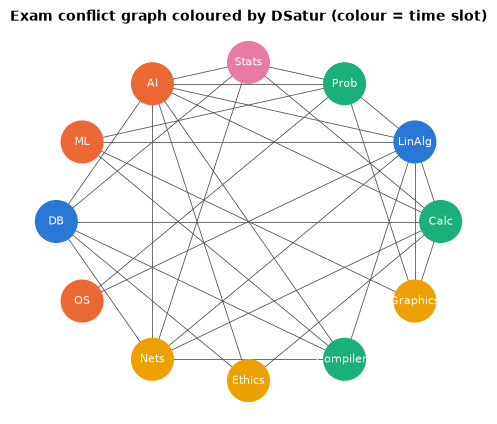

In [14]:
courses = ["Calc", "LinAlg", "Prob", "Stats", "AI", "ML", "DB", "OS", "Nets", "Ethics", "Compilers", "Graphics"]
rng = random.Random(4)
students = [rng.sample(courses, rng.choice([2, 3])) for _ in range(18)]     # each student takes 2 or 3 courses
conflict = nx.Graph(); conflict.add_nodes_from(courses)
for taken in students:
    conflict.add_edges_from(combinations(taken, 2))

dsatur = nx.greedy_color(conflict, strategy="DSATUR")
chi = chromatic_number(conflict)
omega = max(len(c) for c in nx.find_cliques(conflict))
print(f"{conflict.number_of_edges()} conflicts among {len(courses)} courses; DSatur uses {len(set(dsatur.values()))} slots; "
      f"exact χ = {chi}; largest clique ω = {omega}")
slots = defaultdict(list)
for c, s in dsatur.items():
    slots[s].append(c)
for s in sorted(slots):
    print(f"  slot {s + 1}: {', '.join(slots[s])}")
assert all(dsatur[u] != dsatur[v] for u, v in conflict.edges())

fig, ax = plt.subplots(figsize=(6, 5))
draw(conflict, ax, "Exam conflict graph coloured by DSatur (colour = time slot)",
     pos=nx.circular_layout(conflict), node_color=[PALETTE[dsatur[c]] for c in conflict], node_size=900, width=0.6)
plt.show()

---
## 8. Planar graphs and Euler's formula

> **In plain English:** a planar graph can be drawn without crossings, and then dots − lines + regions always equals 2.

**Definition.** A graph is **planar** if it can be drawn in the plane with no edges crossing. Such a drawing divides the plane into **faces** (regions), including the unbounded outer face.

**Euler's formula.** For a connected planar graph drawn without crossings, $V - E + F = 2$.
*Proof by induction on E:* a tree has E = V − 1 and F = 1 (only the outer face), so V − E + F = 2. If G is not a tree, delete an edge on a cycle: it separated two different faces, which merge, so E and F both drop by 1 and V − E + F is unchanged. ∎

**Corollary.** A simple connected planar graph with V ≥ 3 has $E \le 3V - 6$. (Every face is bounded by at least 3 edges and each edge borders at most 2 faces, so 3F ≤ 2E; substitute into Euler's formula.) If it has no triangles (e.g. bipartite), each face has at least 4 edges and $E \le 2V - 4$.
- $K_5$: V = 5, E = 10 > 3·5 − 6 = 9, so **$K_5$ is not planar.**
- $K_{3,3}$: bipartite, V = 6, E = 9 > 2·6 − 4 = 8, so **$K_{3,3}$ is not planar** (the "three utilities" puzzle has no solution).

**Kuratowski's theorem (1930).** A graph is planar iff it contains no subdivision of $K_5$ or $K_{3,3}$. (Wagner's version uses minors.) Planarity can be tested in linear time (Hopcroft and Tarjan, 1974); networkx uses the left-right planarity test.

,V,E,planar?,F,V − E + F,E ≤ 3V − 6 ?
graph,,,,,,
K4,4,6,True,4,2,True
cube Q3,8,12,True,6,2,True
octahedron,6,12,True,8,2,True
dodecahedron,20,30,True,12,2,True
icosahedron,12,30,True,20,2,True
4x5 grid,20,31,True,13,2,True
a random tree,12,11,True,1,2,True
K5,5,10,False,-,-,False
"K3,3",6,9,False,-,-,True


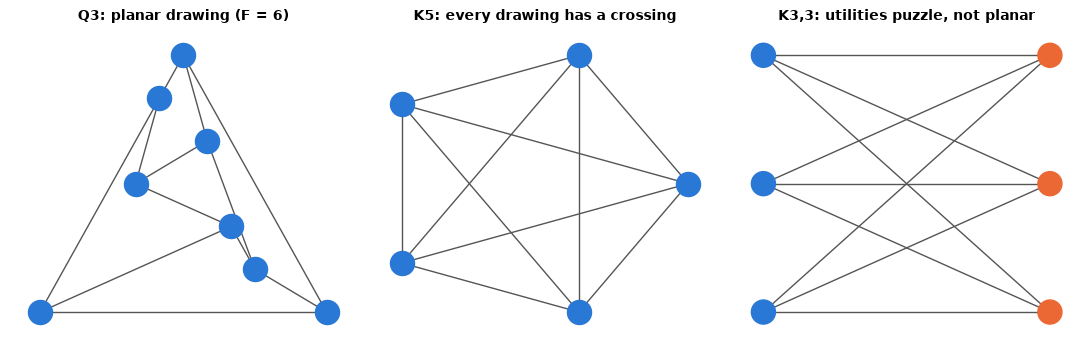

In [15]:
def count_faces(G):
    """Faces of a planar embedding: walk around each face once, marking the half-edges used."""
    planar, emb = nx.check_planarity(G)
    assert planar
    marked, faces = set(), 0
    for u, v in emb.edges():                         # every directed half-edge
        if (u, v) not in marked:
            emb.traverse_face(u, v, mark_half_edges=marked)
            faces += 1
    return faces

rows = []
tests = {"K4": nx.complete_graph(4), "cube Q3": nx.hypercube_graph(3), "octahedron": nx.octahedral_graph(),
         "dodecahedron": nx.dodecahedral_graph(), "icosahedron": nx.icosahedral_graph(),
         "4x5 grid": nx.grid_2d_graph(4, 5), "a random tree": nx.random_labeled_tree(12, seed=0),
         "K5": nx.complete_graph(5), "K3,3": nx.complete_bipartite_graph(3, 3), "Petersen": nx.petersen_graph()}
for name, H in tests.items():
    V, E = H.number_of_nodes(), H.number_of_edges()
    planar, _ = nx.check_planarity(H)
    F = count_faces(H) if planar else None
    rows.append({"graph": name, "V": V, "E": E, "planar?": planar, "F": F if planar else "-",
                 "V − E + F": V - E + F if planar else "-", "E ≤ 3V − 6 ?": E <= 3 * V - 6})
display(pd.DataFrame(rows).set_index("graph"))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
draw(nx.hypercube_graph(3), axes[0], "Q3: planar drawing (F = 6)", pos=nx.planar_layout(nx.hypercube_graph(3)), with_labels=False)
draw(nx.complete_graph(5), axes[1], "K5: every drawing has a crossing", pos=nx.circular_layout(nx.complete_graph(5)), with_labels=False)
K33 = nx.complete_bipartite_graph(3, 3)
draw(K33, axes[2], "K3,3: utilities puzzle, not planar", pos=nx.bipartite_layout(K33, range(3)),
     node_color=[PALETTE[0]] * 3 + [PALETTE[1]] * 3, with_labels=False)
plt.tight_layout(); plt.show()

**What just happened?** For every planar graph, counting faces in networkx's embedding gives V − E + F = 2: the cube has 8 − 12 + 6, the 4×5 grid has 20 − 31 + 13 (12 squares plus the outside), and a tree has F = 1. The Petersen graph passes the edge-count test (15 ≤ 24) but is still not planar (it contains a subdivision of $K_{3,3}$), so **E ≤ 3V − 6 is necessary, not sufficient**.

The five regular polyhedra (cube, octahedron, dodecahedron, icosahedron, tetrahedron = $K_4$) are exactly the planar graphs drawn on a sphere, which is where Euler found his formula. Planarity matters in **circuit and chip layout**: wires on one layer cannot cross.

---
## 9. Matchings: Hall's and König's theorems

> **In plain English:** pair up things on two sides (people and jobs) along the lines, as many pairs as possible.

**Definitions.** A **matching** M is a set of edges with no shared endpoints. It is **maximal** if no edge can be added, **maximum** if it has the largest possible size, and **perfect** if it covers every vertex. A **vertex cover** is a set of vertices touching every edge.

> ⚠️ **Common mistake:** maximal ≠ maximum. On the path a–b–c–d, the single edge {b, c} is a *maximal* matching (nothing can be added) but {a, b}, {c, d} is *maximum*.

**Augmenting paths (Berge, 1957).** An **M-augmenting path** starts and ends at unmatched vertices and alternates non-matching / matching edges. Flipping it increases |M| by one. **Berge's theorem:** M is maximum iff no augmenting path exists. For bipartite graphs, searching for augmenting paths with DFS from each left vertex (**Kuhn's algorithm**) gives a maximum matching in O(V·E). (Hopcroft–Karp improves this to $O(E\sqrt V)$; general graphs need Edmonds' blossom algorithm.)

**Hall's marriage theorem (1935).** A bipartite graph with sides L and R has a matching covering all of L **iff** every subset S ⊆ L has at least |S| neighbours: $|N(S)| \ge |S|$. A set S with $|N(S)| < |S|$ is a **Hall violator**, a certificate that no such matching exists.

**König's theorem (1931).** In a **bipartite** graph, the size of a maximum matching equals the size of a minimum vertex cover.

In [16]:
def max_bipartite_matching(L, adj):
    """Kuhn's augmenting-path algorithm. adj[u] lists the right-side neighbours of u. O(V*E)."""
    match_R = {}                                        # right vertex -> left vertex it is matched to
    def try_augment(u, visited):
        for v in adj[u]:
            if v in visited:
                continue
            visited.add(v)
            if v not in match_R or try_augment(match_R[v], visited):   # v free, or its partner can move
                match_R[v] = u
                return True
        return False
    for u in L:
        try_augment(u, set())
    return {u: v for v, u in match_R.items()}

def hall_violator(L, adj):
    """Brute force over subsets of L: return S with |N(S)| < |S|, or None."""
    for r in range(1, len(L) + 1):
        for S in combinations(L, r):
            NS = set().union(*(adj[u] for u in S))
            if len(NS) < len(S):
                return set(S), NS
    return None

# Job assignment: applicants -> jobs they are qualified for
jobs = {"Ali": ["data eng", "ML eng"], "Sara": ["ML eng"], "Bilal": ["ML eng", "analyst"],
        "Zoya": ["data eng", "analyst", "researcher"], "Omar": ["ML eng", "analyst"]}
M = max_bipartite_matching(list(jobs), jobs)
print("maximum matching:", M, f"(size {len(M)} of {len(jobs)} applicants)")
print("Hall violator:", hall_violator(list(jobs), jobs))

# Check Kuhn against networkx, and König's theorem against a brute-force minimum vertex cover
def min_vertex_cover_size(G):
    nodes = list(G)
    for k in range(len(nodes) + 1):
        for C in combinations(nodes, k):
            Cs = set(C)
            if all(u in Cs or v in Cs for u, v in G.edges()):
                return k

rng = random.Random(9)
for trial in range(150):
    a, b = rng.randint(1, 6), rng.randint(1, 6)
    B = nx.bipartite.random_graph(a, b, rng.random(), seed=trial)
    Lside = [v for v in B if v < a]
    adj = {u: list(B[u]) for u in Lside}
    m_size = len(max_bipartite_matching(Lside, adj))
    assert m_size == len(nx.bipartite.maximum_matching(B, top_nodes=Lside)) // 2
    assert m_size == min_vertex_cover_size(B)                                   # König
    assert (m_size == len(Lside)) == (hall_violator(Lside, adj) is None)       # Hall
print("on 150 random bipartite graphs: Kuhn = networkx, max matching = min vertex cover (König), Hall's condition exact")
tri = nx.complete_graph(3)
print("König fails without bipartiteness: triangle has max matching", len(nx.max_weight_matching(tri)),
      "but min vertex cover", min_vertex_cover_size(tri))

maximum matching: {'Ali': 'data eng', 'Sara': 'ML eng', 'Bilal': 'analyst', 'Zoya': 'researcher'} (size 4 of 5 applicants)
Hall violator: ({'Sara', 'Bilal', 'Omar'}, {'ML eng', 'analyst'})


on 150 random bipartite graphs: Kuhn = networkx, max matching = min vertex cover (König), Hall's condition exact
König fails without bipartiteness: triangle has max matching 1 but min vertex cover 2


**What just happened?** Only 4 of the 5 applicants can be placed, and Hall's theorem explains why: Sara, Bilal and Omar (3 people) are together qualified for only 2 jobs (ML eng, analyst), so one of them must be left out. On 150 random bipartite graphs our augmenting-path algorithm matched networkx, König's equality held every time, and a perfect matching of L existed exactly when no Hall violator did. The triangle shows König's theorem needs bipartiteness (1 ≠ 2).

Weighted versions (the **assignment problem**, solved by the Hungarian algorithm) and the connection to **max-flow / min-cut** are in [`advanced_algorithms/04`](../../00_AI_Fundamentals/advanced_algorithms/04_network_flows_and_matching.ipynb). Matching shows up in ride-hailing (drivers to riders), ad allocation, kidney-exchange programmes, and in object tracking and DETR-style detectors that match predictions to ground-truth boxes.

---
## 10. Spectral graph theory

> **In plain English:** the eigenvalues of a graph's matrix reveal how connected it is and where to cut it.

**Idea.** Write the graph as a matrix and study its eigenvalues and eigenvectors (its **spectrum**). Linear algebra then reveals structure that is hard to see combinatorially. (Eigenvalues are reviewed in [`14_Mathematics/01_linear_algebra.ipynb`](../01_linear_algebra.ipynb).)

**Matrices.** Adjacency A, degree matrix D = diag(deg), and the **(combinatorial) Laplacian** $L = D - A$. The **normalised Laplacian** is $L_{sym} = I - D^{-1/2} A D^{-1/2}$.

**Key facts about L** (for an undirected graph):
1. **Quadratic form:** $x^\top L x = \sum_{\{i,j\} \in E} (x_i - x_j)^2$. So L is symmetric **positive semidefinite**: all eigenvalues $0 = \lambda_1 \le \lambda_2 \le \dots \le \lambda_n$.
2. The all-ones vector gives $L\mathbf{1} = 0$, so 0 is always an eigenvalue.
3. **The multiplicity of eigenvalue 0 equals the number of connected components.** ($x^\top L x = 0$ forces x to be constant on every component.)
4. $\lambda_2$ is the **algebraic connectivity** (Fiedler, 1973): $\lambda_2 > 0$ iff G is connected, and larger $\lambda_2$ means "harder to cut".
5. Its eigenvector, the **Fiedler vector**, solves a relaxed minimum-cut problem: splitting vertices by the **sign** of the Fiedler vector gives a good two-way partition. This is **spectral bisection**, the core of spectral clustering.

In [17]:
def laplacian(G):
    A_ = nx.to_numpy_array(G, nodelist=sorted(G))
    return np.diag(A_.sum(axis=1)) - A_

# Fact 1: the quadratic form, checked on a random graph and random vectors
G = nx.gnp_random_graph(12, 0.3, seed=0)
L = laplacian(G)
for _ in range(100):
    x = np.random.randn(12)
    assert np.isclose(x @ L @ x, sum((x[i] - x[j]) ** 2 for i, j in G.edges()))
print("x^T L x = sum over edges of (x_i - x_j)^2: verified")

# Fact 3: number of zero eigenvalues = number of components
for seed in range(50):
    H = nx.gnp_random_graph(20, 0.08, seed=seed)
    eig = np.linalg.eigvalsh(laplacian(H))
    assert np.all(eig > -1e-9)                                            # PSD
    assert np.sum(eig < 1e-9) == nx.number_connected_components(H)
print("multiplicity of eigenvalue 0 = number of components: verified on 50 random graphs")

# Fact 4: algebraic connectivity of graphs that are easy / hard to cut (all with 10 vertices)
rows = []
for name, H in {"path P10": nx.path_graph(10), "cycle C10": nx.cycle_graph(10), "star": nx.star_graph(9),
                "barbell (two K5 joined by one edge)": nx.barbell_graph(5, 0), "Petersen": nx.petersen_graph(),
                "complete K10": nx.complete_graph(10)}.items():
    eig = np.linalg.eigvalsh(laplacian(H))
    rows.append({"graph": name, "edges": H.number_of_edges(), "λ2 (algebraic connectivity)": round(eig[1], 4),
                 "edge connectivity": nx.edge_connectivity(H)})
display(pd.DataFrame(rows).set_index("graph").sort_values("λ2 (algebraic connectivity)"))

x^T L x = sum over edges of (x_i - x_j)^2: verified
multiplicity of eigenvalue 0 = number of components: verified on 50 random graphs


,edges,λ2 (algebraic connectivity),edge connectivity
graph,,,
path P10,9,0.0979,1
barbell (two K5 joined by one edge),21,0.2984,1
cycle C10,10,0.3820,2
star,9,1.0000,1
Petersen,15,2.0000,3
complete K10,45,10.0000,9


**What just happened?** Both facts held on every random graph. In the table the graphs with a **bottleneck** (the path, and the barbell whose two halves hang on one edge) have tiny $\lambda_2$ (about 0.1 and 0.3), while the complete graph has $\lambda_2 = n = 10$. Fiedler proved $\lambda_2 \le$ the vertex and edge connectivity for non-complete graphs, and the table agrees.

### Spectral bisection on a graph with two hidden communities
We plant two communities of 25 vertices each: edges inside a community appear with probability 0.3, edges between communities with probability 0.03 (a **stochastic block model**). Then we split by the sign of the Fiedler vector and compare with the hidden truth.

190 edges, λ2 = 0.752, λ3 = 2.502
spectral bisection recovers the hidden communities with accuracy 100%, cutting 12 edges


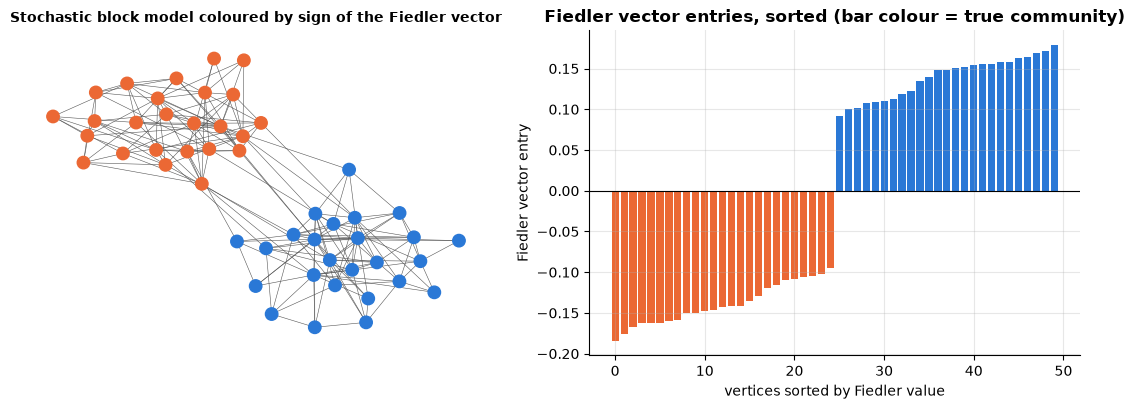

In [18]:
sizes, probs = [25, 25], [[0.3, 0.03], [0.03, 0.3]]
SBM = nx.stochastic_block_model(sizes, probs, seed=4)
truth = np.array([0] * 25 + [1] * 25)
L = laplacian(SBM)
eigvals, eigvecs = np.linalg.eigh(L)
fiedler = eigvecs[:, 1]
pred = (fiedler > 0).astype(int)
accuracy = max(np.mean(pred == truth), np.mean(pred != truth))          # the sign of an eigenvector is arbitrary
cut = sum(1 for u, v in SBM.edges() if pred[u] != pred[v])
print(f"{SBM.number_of_edges()} edges, λ2 = {eigvals[1]:.3f}, λ3 = {eigvals[2]:.3f}")
print(f"spectral bisection recovers the hidden communities with accuracy {accuracy:.0%}, cutting {cut} edges")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pos = nx.spring_layout(SBM, seed=2)
draw(SBM, axes[0], "Stochastic block model coloured by sign of the Fiedler vector",
     pos=pos, node_color=[PALETTE[p] for p in pred], with_labels=False, node_size=80, width=0.4)
order = np.argsort(fiedler)
axes[1].bar(range(50), fiedler[order], color=[PALETTE[t] for t in truth[order]])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Fiedler vector entries, sorted (bar colour = true community)")
axes[1].set_xlabel("vertices sorted by Fiedler value"); axes[1].set_ylabel("Fiedler vector entry")
plt.tight_layout(); plt.show()

**What just happened?** The sorted Fiedler vector has a clear jump through zero, and the sign alone recovers the planted communities. There is a noticeable gap between $\lambda_2$ and $\lambda_3$: with k clear communities, the first k eigenvalues are small and then the spectrum jumps (the **eigengap heuristic** for choosing k).

**From here to spectral clustering and GNNs.**
- **Spectral clustering** (Shi and Malik, 2000; Ng, Jordan and Weiss, 2001) builds a similarity graph between data points, takes the first k eigenvectors of the normalised Laplacian as new coordinates, and runs k-means on them ([`03_Machine_Learning/02_unsupervised/01_clustering.ipynb`](../../03_Machine_Learning/02_unsupervised/01_clustering.ipynb)).
- A **graph convolutional network** layer (Kipf and Welling, 2017) computes $H' = \sigma(\hat A H W)$ with $\hat A = \tilde D^{-1/2}(A + I)\tilde D^{-1/2}$. Multiplying by $\hat A$ replaces each node's features with a weighted average of its own and its neighbours' features: a low-pass filter on the graph spectrum ([`05_Deep_Learning/07_gnn.ipynb`](../../05_Deep_Learning/07_gnn.ipynb)). The cell below shows that two rounds of this averaging clean up noisy node features on the same graph.

In [19]:
A_ = nx.to_numpy_array(SBM, nodelist=range(50))
A_tilde = A_ + np.eye(50)                                    # add self-loops
d_inv_sqrt = 1 / np.sqrt(A_tilde.sum(axis=1))
A_hat = d_inv_sqrt[:, None] * A_tilde * d_inv_sqrt[None, :]  # D^-1/2 (A + I) D^-1/2

rng_np = np.random.default_rng(0)
x = (2 * truth - 1) + rng_np.normal(0, 2.0, size=50)         # +1 / -1 community signal buried in noise
for k in range(4):
    h = np.linalg.matrix_power(A_hat, k) @ x                 # k rounds of neighbour averaging
    acc = np.mean((h > 0).astype(int) == truth)
    print(f"after {k} GCN propagation steps: accuracy of sign(feature) = {acc:.0%}")

after 0 GCN propagation steps: accuracy of sign(feature) = 78%
after 1 GCN propagation steps: accuracy of sign(feature) = 100%
after 2 GCN propagation steps: accuracy of sign(feature) = 100%
after 3 GCN propagation steps: accuracy of sign(feature) = 100%


**What just happened?** The raw feature is mostly noise (a noise standard deviation of 2 against a signal of ±1), so its sign is right for only 78% of the nodes. Each multiplication by $\hat A$ averages a node with its neighbours, who are mostly in the same community, so the noise cancels while the community signal survives. After a single step the sign already recovers the communities perfectly on this graph. Averaging too many times makes all features in a connected graph converge to the same value; this is **over-smoothing**, a known limit on GNN depth.

---
## 11. Random graphs

> **In plain English:** if lines are added at random, the graph suddenly changes character at sharp thresholds.

**Erdős–Rényi model** $G(n, p)$ (Gilbert 1959; Erdős and Rényi 1959–60): each of the $\binom n2$ possible edges is present independently with probability p. Expected number of edges $p\binom n2$; each degree is Binomial(n − 1, p), close to Poisson(c) with mean $c = p(n-1)$ when n is large.

**Phase transitions** (for large n, with c = np):
- **Giant component:** if c < 1, all components are small (size O(log n)); if c > 1, a unique **giant component** holds a fraction S > 0 of the vertices, where S solves $S = 1 - e^{-cS}$.
- **Connectivity:** $G(n, p)$ becomes connected around $p = \ln n / n$. Below it, isolated vertices remain; above it, they disappear.

This is the same kind of sharp threshold as water freezing, and it is why network epidemics and information cascades either fizzle out or spread widely.

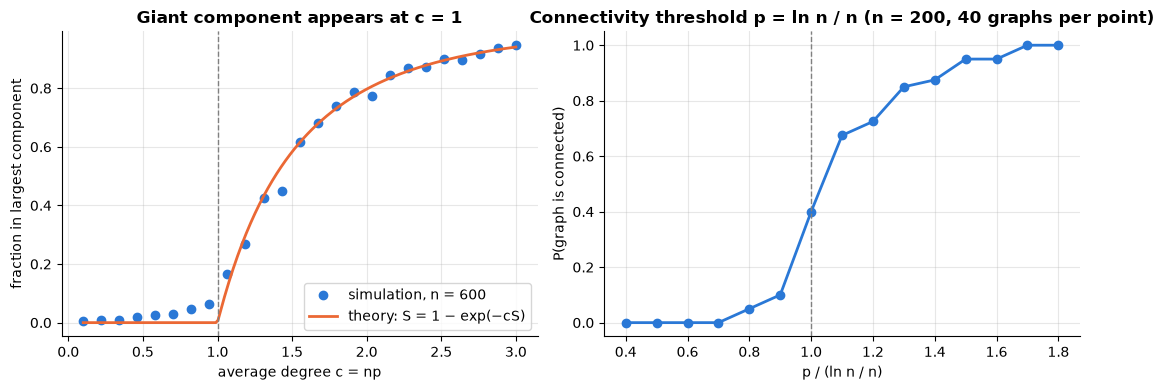

theory at c = 2: S = 0.797; simulation at c ≈ 2: 0.772


In [20]:
n = 600
cs = np.linspace(0.1, 3.0, 25)
sim = []
for c in cs:
    fr = []
    for rep in range(3):
        G = nx.fast_gnp_random_graph(n, c / (n - 1), seed=int(1000 * c) + rep)
        fr.append(max(len(cc) for cc in nx.connected_components(G)) / n)
    sim.append(np.mean(fr))

def giant_theory(c):
    S = 0.5
    for _ in range(500):
        S = 1 - math.exp(-c * S)                                  # fixed-point iteration
    return S if c > 1 else 0.0

n2 = 200
mult = np.linspace(0.4, 1.8, 15)
p_conn = []
for a in mult:
    p = a * math.log(n2) / n2
    p_conn.append(np.mean([nx.is_connected(nx.fast_gnp_random_graph(n2, p, seed=s)) for s in range(40)]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cs, sim, "o", label=f"simulation, n = {n}")
cc_ = np.linspace(0.1, 3, 200)
axes[0].plot(cc_, [giant_theory(c) for c in cc_], label="theory: S = 1 − exp(−cS)")
axes[0].axvline(1, color="gray", ls="--", lw=1)
axes[0].set_xlabel("average degree c = np"); axes[0].set_ylabel("fraction in largest component")
axes[0].set_title("Giant component appears at c = 1"); axes[0].legend()
axes[1].plot(mult, p_conn, "o-")
axes[1].axvline(1, color="gray", ls="--", lw=1)
axes[1].set_xlabel("p / (ln n / n)"); axes[1].set_ylabel("P(graph is connected)")
axes[1].set_title(f"Connectivity threshold p = ln n / n (n = {n2}, 40 graphs per point)")
plt.tight_layout(); plt.show()
print(f"theory at c = 2: S = {giant_theory(2):.3f}; simulation at c ≈ 2: {sim[int(np.argmin(abs(cs - 2)))]:.3f}")

**What just happened?** Below average degree 1 the largest component is a tiny fraction of the graph; just above 1 a giant component appears and grows along the theoretical curve (at c = 2 the theory predicts 79.7% of the vertices; this simulation gives 77%). The right panel shows the second threshold: graphs with $p$ well below $\ln n / n$ are almost never connected, and well above it almost always are. (At finite n the transitions are smoothed a little.)

### Real networks are not Erdős–Rényi
Real social, web and citation networks have two features that $G(n, p)$ lacks:
- **Small world with high clustering** (Watts and Strogatz, 1998): friends of friends are often friends (high clustering coefficient), yet path lengths are short. The Watts–Strogatz model starts from a ring lattice (high clustering, long paths) and rewires each edge with probability p. A few random "shortcuts" collapse the path length while clustering stays high.
- **Scale-free degree distributions** (Barabási and Albert, 1999): a few hubs have enormous degree. The BA model grows the graph by **preferential attachment** (new nodes link to existing nodes with probability proportional to their degree), which gives a power-law tail $P(k) \sim k^{-3}$ instead of the thin Poisson tail.

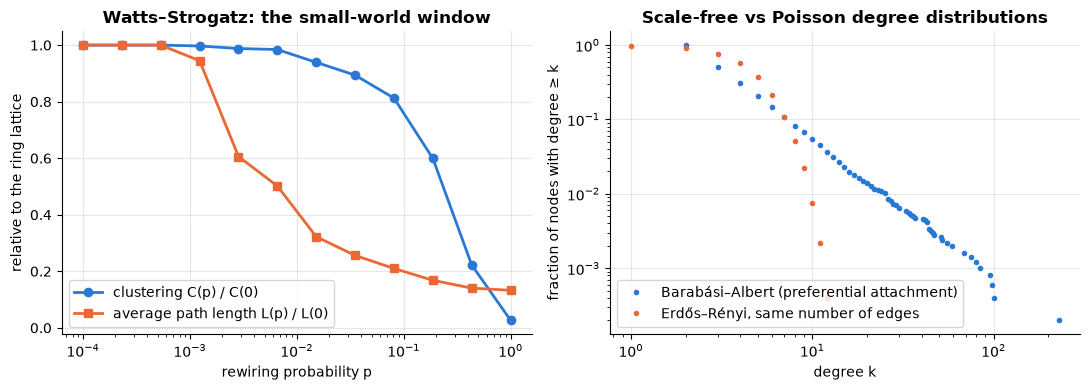

at p ≈ 0.007: path length fell to 50% of the lattice's while clustering kept 98%
max degree: BA 228, ER 12 (both average degree 4.0)


In [21]:
n, k = 300, 6
ps = np.logspace(-4, 0, 12)
base = nx.watts_strogatz_graph(n, k, 0, seed=0)
C0, L0 = nx.average_clustering(base), nx.average_shortest_path_length(base)
Cs, Ls = [], []
for p in ps:
    G = nx.connected_watts_strogatz_graph(n, k, p, seed=1)
    Cs.append(nx.average_clustering(G) / C0)
    Ls.append(nx.average_shortest_path_length(G) / L0)

BA = nx.barabasi_albert_graph(5000, 2, seed=0)
ER = nx.gnm_random_graph(5000, BA.number_of_edges(), seed=0)               # same number of edges

def ccdf(G):
    d = np.array(sorted(dict(G.degree()).values()))
    ks = np.unique(d)
    return ks, np.array([np.mean(d >= k_) for k_ in ks])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(ps, Cs, "o-", label="clustering C(p) / C(0)")
axes[0].semilogx(ps, Ls, "s-", label="average path length L(p) / L(0)")
axes[0].set_xlabel("rewiring probability p"); axes[0].set_ylabel("relative to the ring lattice")
axes[0].set_title("Watts–Strogatz: the small-world window"); axes[0].legend()
for G_, name in [(BA, "Barabási–Albert (preferential attachment)"), (ER, "Erdős–Rényi, same number of edges")]:
    ks, frac = ccdf(G_)
    axes[1].loglog(ks, frac, "o", ms=3, label=name)
axes[1].set_xlabel("degree k"); axes[1].set_ylabel("fraction of nodes with degree ≥ k")
axes[1].set_title("Scale-free vs Poisson degree distributions"); axes[1].legend()
plt.tight_layout(); plt.show()
i = int(np.argmin(abs(ps - 0.01)))
print(f"at p ≈ {ps[i]:.3f}: path length fell to {Ls[i]:.0%} of the lattice's while clustering kept {Cs[i]:.0%}")
print(f"max degree: BA {max(d for _, d in BA.degree())}, ER {max(d for _, d in ER.degree())} (both average degree {2 * BA.number_of_edges() / 5000:.1f})")

**What just happened?** In the left panel, at p ≈ 0.007 (rewiring under 1% of the edges) the average path length has already halved while clustering keeps 98% of its lattice value: that window is the **small world**. In the right panel the Erdős–Rényi degrees die off quickly, while the Barabási–Albert graph has a straight-line (power-law) tail on the log–log plot and hubs with degree an order of magnitude larger than anything in the ER graph with the same number of edges. Hubs matter in practice: they make networks robust to random failures but fragile to targeted attacks, and they dominate the spread of information.

---
## 12. Summary of theorems

> **In plain English:** every theorem in this notebook on one page.

| Theorem | Statement | Checked here by |
|---|---|---|
| Handshake lemma | $\sum \deg = 2\lvert E\rvert$; even number of odd vertices | 500 random graphs |
| Havel–Hakimi | recursive test for graphical degree sequences | vs `nx.is_graphical` |
| Walks | $(A^k)_{ij}$ = walks of length k; triangles = tr(A³)/6 | brute-force walk counting |
| König (bipartite) | bipartite ⇔ no odd cycle | BFS returns an odd cycle certificate |
| Tree characterisations | connected+acyclic ⇔ connected+(n−1 edges) ⇔ … | 1,500 random graphs |
| Cayley | $n^{n-2}$ labelled trees | brute force + Prüfer bijection |
| Matrix-tree (Kirchhoff) | spanning trees = any cofactor of L | brute force |
| Euler | Euler circuit ⇔ connected and all degrees even | Hierholzer, de Bruijn |
| Dirac / Ore | sufficient conditions for Hamiltonian cycles | (the exact problem is NP-complete) |
| Colouring bounds | ω ≤ χ ≤ Δ + 1; Brooks; four colour theorem | exact χ by backtracking |
| Euler's formula | V − E + F = 2; E ≤ 3V − 6; K₅, K₃,₃ non-planar | faces of networkx embeddings |
| Hall | perfect matching of L ⇔ $\lvert N(S)\rvert \ge \lvert S\rvert$ for all S ⊆ L | brute force |
| König–Egerváry | bipartite: max matching = min vertex cover | brute force |
| Spectral | #components = multiplicity of 0 in L; Fiedler bisection | random graphs, SBM |
| Erdős–Rényi | giant component at c = 1; connected at p = ln n / n | simulation |

---
## 13. 🔗 How this connects to modern AI

> **In plain English:** graphs are everywhere in AI: knowledge graphs, graph neural networks, matching losses and PageRank.

| Graph theory idea | Where it lives in AI |
|---|---|
| Directed labelled graphs | **Knowledge graphs** (Wikidata, enterprise KGs) and **GraphRAG**, which retrieves connected facts for an LLM ([`08_LLM/09_knowledge_graphs`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb), [`13_Databases/07_graph_databases`](../../13_Databases/07_graph_databases/01_graph_databases.ipynb)) |
| Adjacency / Laplacian matrices | **Graph neural networks**: message passing multiplies node features by a normalised adjacency (Section 10), **spectral clustering**, graph signal processing ([`05_Deep_Learning/07_gnn.ipynb`](../../05_Deep_Learning/07_gnn.ipynb)) |
| Random walks, Markov chains | **PageRank** (below), node2vec / DeepWalk embeddings (random walks fed to word2vec), label propagation |
| Matchings | the **Hungarian matching loss** in DETR object detectors; assigning tracks to detections in video ([`06_Computer_Vision/08_video_analysis.ipynb`](../../06_Computer_Vision/08_video_analysis.ipynb)); ride-hailing and ad allocation |
| Colouring | register allocation in ML compilers; scheduling GPU jobs that cannot share a resource |
| Trees, DAGs | decision trees, parse trees, computation graphs for autograd |
| Isomorphism | molecules as graphs: deciding whether two molecules are the same; the **Weisfeiler–Lehman test** bounds what message-passing GNNs can distinguish (Xu et al., 2019) |
| Random graph models | synthetic benchmarks for graph ML; epidemic and misinformation spread models; recommender-system user–item graphs |

### PageRank: a random surfer on a Markov chain
**PageRank** (Brin and Page, 1998) models a surfer who, at each step, follows a random outgoing link with probability α = 0.85 and jumps to a uniformly random page with probability 1 − α. A page's score is the long-run fraction of time the surfer spends there: the **stationary distribution** π of a Markov chain, satisfying
$$\pi_j = \frac{1-\alpha}{n} + \alpha \sum_{i \to j} \frac{\pi_i}{\text{outdeg}(i)}.$$
Pages with no outgoing links ("dangling") are treated as linking to every page. The teleport makes the chain irreducible and aperiodic, so π is unique and **power iteration** (apply the update until it stops changing) converges geometrically with rate α. This is the power method for the dominant eigenvector of the "Google matrix".

In [22]:
def pagerank(G, alpha=0.85, tol=1e-12, max_iter=1000):
    """PageRank by power iteration on a directed graph (dangling nodes jump uniformly)."""
    nodes = list(G)
    n = len(nodes)
    idx = {v: i for i, v in enumerate(nodes)}
    out_deg = np.array([G.out_degree(v) for v in nodes], dtype=float)
    pi = np.full(n, 1 / n)
    for it in range(max_iter):
        new = np.full(n, (1 - alpha) / n)
        dangling_mass = pi[out_deg == 0].sum()
        new += alpha * dangling_mass / n                 # dangling pages link to everyone
        for u, v in G.edges():
            new[idx[v]] += alpha * pi[idx[u]] / out_deg[idx[u]]
        if np.abs(new - pi).sum() < tol:
            return dict(zip(nodes, new)), it + 1
        pi = new
    return dict(zip(nodes, pi)), max_iter

web = nx.DiGraph([("home", "about"), ("home", "blog"), ("home", "shop"), ("about", "home"),
                  ("blog", "home"), ("blog", "post1"), ("blog", "post2"), ("post1", "blog"),
                  ("post2", "blog"), ("post2", "post1"), ("shop", "home"), ("shop", "cart"),
                  ("cart", "checkout")])                               # 'checkout' is dangling
pr, iters = pagerank(web)
ref = nx.pagerank(web, alpha=0.85, tol=1e-12)
assert all(abs(pr[v] - ref[v]) < 1e-8 for v in web)
print(f"converged in {iters} iterations; matches networkx.pagerank")
display(pd.Series(pr, name="PageRank").sort_values(ascending=False).round(4).to_frame())

big = nx.gnp_random_graph(300, 0.02, directed=True, seed=1)
pr_big, it_big = pagerank(big)
assert max(abs(pr_big[v] - x) for v, x in nx.pagerank(big, tol=1e-12).items()) < 1e-8
print(f"random 300-page web: {it_big} iterations, matches networkx; scores sum to {sum(pr_big.values()):.6f}")

converged in 74 iterations; matches networkx.pagerank


,PageRank
blog,0.2435
home,0.2057
post1,0.1374
post2,0.0964
shop,0.0857
about,0.0857
checkout,0.0817
cart,0.0639


random 300-page web: 28 iterations, matches networkx; scores sum to 1.000000


**What just happened?** Our power iteration agrees with `nx.pagerank` to 8 decimal places. "blog" and "home" rank highest because many pages link to them and they receive links from well-ranked pages. "checkout" has no outgoing links, and the dangling-node rule spreads its mass evenly. The scores form a probability distribution (they sum to 1).

---
## 14. Recap

> **In plain English:** the key facts to remember, then practice.

- A graph is (V, E). **Handshake lemma:** degrees sum to 2|E|, so the number of odd-degree vertices is even. **Havel–Hakimi** decides whether a degree sequence is possible.
- $(A^k)_{ij}$ counts walks of length k; components, bridges and cut vertices describe connectivity.
- **Bipartite ⇔ no odd cycle**; BFS 2-colouring finds the sides or an odd cycle.
- **Isomorphism** needs an explicit bijection; invariants can only disprove it. The problem is in NP and has a quasi-polynomial algorithm.
- **Trees**: six equivalent definitions (connected + acyclic, n − 1 edges, unique paths, …). **Cayley**: $n^{n-2}$ labelled trees (Prüfer bijection). **Kirchhoff**: spanning trees = Laplacian cofactor.
- **Euler circuit ⇔ connected and all degrees even** (Hierholzer, O(m)); Hamiltonian cycle is NP-complete with only sufficient conditions (Dirac, Ore).
- **Colouring:** ω ≤ χ ≤ Δ + 1; χ ≤ 2 ⇔ bipartite; greedy depends on order; four colour theorem for planar graphs; timetabling and register allocation.
- **Planarity:** V − E + F = 2, E ≤ 3V − 6 (≤ 2V − 4 if triangle-free), so K₅ and K₃,₃ are not planar; Kuratowski.
- **Matchings:** augmenting paths (Berge), **Hall's condition**, **König's theorem** for bipartite graphs.
- **Spectral:** L = D − A is PSD; zeros of the spectrum count components; λ₂ measures connectivity; the Fiedler vector bisects; GCNs average over a normalised adjacency.
- **Random graphs:** giant component at average degree 1, connectivity at p = ln n / n; real networks are small-world and scale-free.
- **PageRank** is the stationary distribution of a random surfer, computed by power iteration.

## Practice problems

**1. (Easy, conceptual)** Can a graph have degree sequence (5, 4, 3, 2, 2, 1)? (4, 4, 4, 4, 2)? Explain with the handshake lemma and Havel–Hakimi.

<details><summary>Show solution</summary>

(5, 4, 3, 2, 2, 1): the sum is 17, which is odd, so **no** (handshake lemma).
(4, 4, 4, 4, 2): sum 18 is even. Havel–Hakimi: remove 4, subtract 1 from the next four → (3, 3, 3, 1); remove 3 → (2, 2, 0); remove 2 → (1, −1): negative, so **not graphical**. Intuition: in a 5-vertex simple graph, a degree-4 vertex is adjacent to everyone, so four such vertices force the last vertex to have degree 4, not 2. `havel_hakimi([4, 4, 4, 4, 2])` returns `False`.

</details>

**2. (Easy, coding)** A **cut vertex** is a vertex whose removal increases the number of components. Write a brute-force finder and check it against `nx.articulation_points` on random graphs.

<details><summary>Show solution</summary>

```python
import networkx as nx

def components_after_removing(G, v):
    H = G.copy(); H.remove_node(v)
    return nx.number_connected_components(H)

def cut_vertices_brute(G):
    base = nx.number_connected_components(G)
    return {v for v in G if components_after_removing(G, v) > base}

G = nx.Graph([(0, 1), (1, 2), (2, 0), (2, 3), (3, 4), (4, 5), (5, 3), (5, 6)])
print(sorted(cut_vertices_brute(G)), sorted(nx.articulation_points(G)))     # [2, 3, 5] [2, 3, 5]
for seed in range(100):
    H = nx.gnp_random_graph(12, 0.2, seed=seed)
    assert cut_vertices_brute(H) == set(nx.articulation_points(H))
```

</details>

**3. (Medium, proof)** Prove that every tree with n ≥ 2 vertices has at least two leaves. Then use it to prove that a tree with n vertices has n − 1 edges.

<details><summary>Show solution</summary>

*At least two leaves:* take a **longest path** $v_0 v_1 \dots v_k$ (k ≥ 1 since there is an edge). If $v_0$ had another neighbour w ≠ $v_1$, then either w is on the path (giving a cycle, impossible in a tree) or not (giving a longer path, contradicting maximality). So deg($v_0$) = 1, and likewise for $v_k$. ∎

*n − 1 edges, by induction on n:* n = 1: 0 edges. ✓ For n ≥ 2, remove a leaf and its edge. The rest is still connected (no path between other vertices passed through a leaf) and acyclic, so it is a tree with n − 1 vertices and, by the IH, n − 2 edges. Adding the leaf back gives n − 1 edges. ∎

</details>

**4. (Medium)** Can the "envelope" (a square with both diagonals, plus a roof triangle on top) be drawn without lifting the pen and without retracing a line? Decide with Euler's theorem and check in code.

<details><summary>Show solution</summary>

Vertices 0–3 form the square with diagonals (each has degree 3), the roof apex 4 joins 2 and 3. Degrees: 0 → 3, 1 → 3, 2 → 4, 3 → 4, 4 → 2. Exactly **two** odd vertices (0 and 1), so an Euler **path** exists; it must start at 0 and end at 1 (or vice versa).

```python
import networkx as nx

def has_euler_path(edges):
    G = nx.MultiGraph(edges)
    if not nx.is_connected(G):
        return False
    odd = [v for v, d in G.degree() if d % 2]
    return len(odd) in (0, 2)

envelope = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2), (1, 3), (2, 4), (3, 4)]   # house with an X and a roof
print(has_euler_path(envelope), nx.has_eulerian_path(nx.MultiGraph(envelope)))  # True True
```

</details>

**5. (Medium, coding)** Count the proper colourings of the 5-cycle with k = 1, 2, 3, 4 colours by brute force. What does this say about χ(C₅)? Compare with the formula $(k-1)^n + (-1)^n(k-1)$.

<details><summary>Show solution</summary>

```python
import networkx as nx
from itertools import product

def is_proper(G, colouring):
    return all(colouring[u] != colouring[v] for u, v in G.edges())

def count_colourings(G, k):
    """Number of proper colourings with k colours (the chromatic polynomial at k), by brute force."""
    nodes = list(G)
    return sum(is_proper(G, dict(zip(nodes, c))) for c in product(range(k), repeat=len(nodes)))

C5 = nx.cycle_graph(5)
print([count_colourings(C5, k) for k in range(1, 5)])                  # [0, 0, 30, 240]
# formula for a cycle: (k-1)^n + (-1)^n (k-1)
assert all(count_colourings(C5, k) == (k - 1) ** 5 - (k - 1) for k in range(1, 5))
```
There are 0 colourings with 1 or 2 colours and 30 with 3, so χ(C₅) = 3 (odd cycle, not bipartite). The count as a function of k is the **chromatic polynomial**; for $C_n$ it is $(k-1)^n + (-1)^n(k-1)$.

</details>

**6. (Medium, conceptual)** Is the cube graph Q₃ bipartite? Planar? Hamiltonian? What is its chromatic number?

<details><summary>Show solution</summary>

- **Bipartite:** yes; split vertices by the parity of the number of 1-bits (each edge flips one bit). So χ(Q₃) = 2.
- **Planar:** yes (Section 8 drew it with F = 6: 8 − 12 + 6 = 2).
- **Hamiltonian:** yes; the **Gray code** 000, 001, 011, 010, 110, 111, 101, 100 (and back to 000) visits every vertex once, changing one bit per step. Every hypercube $Q_d$ with d ≥ 2 is Hamiltonian this way.

</details>

**7. (Hard, coding + maths)** Compute the Laplacian spectrum of $K_n$ and $C_n$ for n = 8 and check the closed forms: $K_n$ has eigenvalues 0 (once) and n (n − 1 times); $C_n$ has $2 - 2\cos(2\pi k/n)$ for k = 0, …, n − 1. Which one has the larger algebraic connectivity, and why does that make sense?

<details><summary>Show solution</summary>

```python
import numpy as np
import networkx as nx

def laplacian_spectrum(G):
    A = nx.to_numpy_array(G)
    return np.sort(np.linalg.eigvalsh(np.diag(A.sum(1)) - A))

n = 8
print(np.round(laplacian_spectrum(nx.complete_graph(n)), 6) + 0.0)   # [0, 8, 8, 8, 8, 8, 8, 8]
print(np.round(laplacian_spectrum(nx.cycle_graph(n)), 6) + 0.0)
expected = np.sort([2 - 2 * np.cos(2 * np.pi * k / n) for k in range(n)])
assert np.allclose(laplacian_spectrum(nx.cycle_graph(n)), expected)
assert np.allclose(laplacian_spectrum(nx.complete_graph(n)), [0] + [n] * (n - 1))
```
$\lambda_2(K_8) = 8$, while $\lambda_2(C_8) = 2 - 2\cos(\pi/4) \approx 0.586$. The complete graph needs 7 edges cut to isolate even one vertex, while the cycle falls apart after cutting only 2 edges, so it is far easier to disconnect.

</details>

**8. (Hard, coding)** Zachary's karate club (1977) split into two clubs after a dispute. Use spectral bisection (the sign of the Fiedler vector) on `nx.karate_club_graph()` and count how many members it assigns to the club they actually joined (the `club` node attribute).

<details><summary>Show solution</summary>

```python
import numpy as np
import networkx as nx

def fiedler_split(G):
    nodes = sorted(G)
    A = nx.to_numpy_array(G, nodelist=nodes)
    L = np.diag(A.sum(1)) - A
    vals, vecs = np.linalg.eigh(L)
    f = vecs[:, 1]
    return {v for v, x in zip(nodes, f) if x > 0}, {v for v, x in zip(nodes, f) if x <= 0}

G = nx.karate_club_graph()                                   # ships with networkx (no download)
S, T = fiedler_split(G)
truth = {v for v in G if G.nodes[v]["club"] == "Mr. Hi"}
agree = max(len(S & truth) + len(T - truth), len(T & truth) + len(S - truth))
print(f"{agree} of {len(G)} members assigned to the club they actually joined")
```
Spectral bisection puts **33 of the 34** members in the club they really joined, using **only** who was friends with whom.

</details>

## Further reading

- K. H. Rosen, *Discrete Mathematics and Its Applications*, 8th ed. (2019): ch. 10 (graphs) and ch. 11 (trees).
- D. B. West, *Introduction to Graph Theory*, 2nd ed. (2001): the standard undergraduate text, with full proofs of Hall, König, Kuratowski and Brooks.
- R. Diestel, *Graph Theory*, 6th ed. (2025): a rigorous graduate text; the author provides a free electronic edition.
- D. A. Spielman, *Spectral and Algebraic Graph Theory* (Yale lecture notes, free online).
- A.-L. Barabási, *Network Science* (Cambridge, 2016; free online at networksciencebook.com): random graphs, small worlds and scale-free networks.

## Next notebook

➡️ [`04_automata_and_regular_languages.ipynb`](04_automata_and_regular_languages.ipynb): finite automata are graphs whose edges are labelled by characters. We build DFAs and NFAs, convert regular expressions into automata, minimise them, prove that some languages are not regular, and use an automaton to force an LLM's output to match a pattern.